<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/knn_clustering_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import os
import kagglehub

# Download latest version of Iris dataset
path = kagglehub.dataset_download("uciml/iris")
print("Path to dataset files:", path)

# Find the CSV file in the downloaded path
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    iris_file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(iris_file_path)
    print("Dataset loaded successfully!")
    display(df.head())
else:
    print("No CSV file found in the downloaded dataset path.")

Using Colab cache for faster access to the 'iris' dataset.
Path to dataset files: /kaggle/input/iris
Dataset loaded successfully!


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


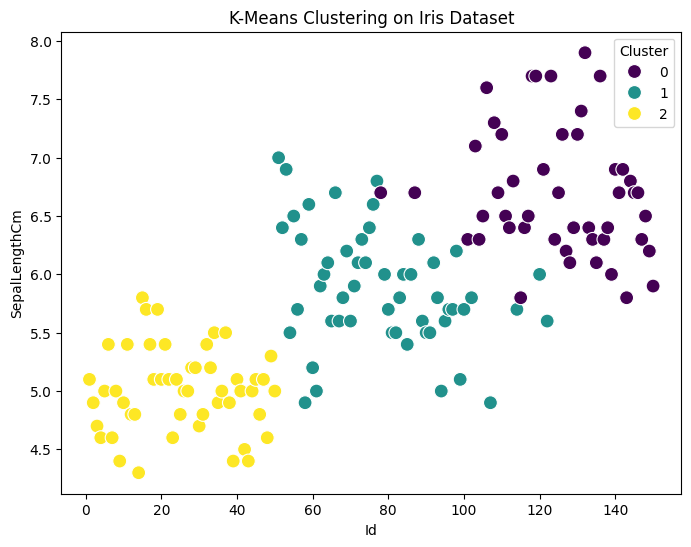

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare features for clustering (excluding any label/species column if present)
features = df.select_dtypes(include=['float64', 'int64'])

# Scale the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Apply K-Means (K=3 for Iris dataset)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(scaled_features)

# Visualize the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x=features.columns[0], y=features.columns[1], hue='Cluster', palette='viridis', s=100)
plt.title('K-Means Clustering on Iris Dataset')
plt.xlabel(features.columns[0])
plt.ylabel(features.columns[1])
plt.show()